# dict_HMM, default parameters

This notebook runs the theme and song stage of dict_HMM and summarizes the fit.

`hmm_run` is the C program in `analysis/dict_HMM/c`. It has no command-line parameters. The constants below are compiled into it. The input is the 2367 kept placements of the 35-motif dictionary on wav 2 (`SOCAL_H_76_230427_011115.x`) and wav 3 (`SOCAL_H_76_230427_014845.x`), joined so wav 3 starts at 37.5 minutes. Dictionary learning is not repeated here: the C learner has no loader for the GPL windows, and its seed generator is not the NumPy PCG64 generator that produced those 35 motifs.


## Defaults

Learning, used to build the dictionary these placements come from:

| Name | Value |
|---|---:|
| `k` | 1 |
| `eps` | 0.01 |
| `w_min`, `w_max` | 10, 40 |
| `seeds_per_pass` | 10 |
| `n_min` | 10 |
| `refine_iters` | 2 |
| `tau` | 0.4 |
| `max_outer` | 50 |
| `min_coverage` | 0.7 |
| `n_components` | 5 |

Placement on a finished dictionary uses the same `k`, `eps`, and `tau`, with `n_min` = 1.

The HMM stage that this notebook runs:

| Name | Value |
|---|---:|
| `n_themes` | 4, cycle 0 → 1 → 2 → 3 → 0 |
| `n_themes_before_merge` | 5, then the two neighboring motif-21 themes are merged |
| `bin_minutes` | 0.5 |
| `alpha` | 0.3 |
| `duration_min_bins`, `duration_max_bins` | 2, 60 |
| `duration_sigma_floor` | 0.25 |
| `likelihood_gap` | 1.920729410347062 |
| recording | 75 minutes from the start of wav 2 |
| unix origin | 1682557875, 2023-04-27 01:11:15 UTC |


In [1]:
import os
import subprocess
from pathlib import Path

ROOT = Path("/home/yfreund/projects/panMP_whales/analysis/dict_HMM")
C = ROOT / "c"
OUT = ROOT / "results"
OUT.mkdir(exist_ok=True)
env = os.environ.copy()
env["PYTHONPATH"] = "/home/yfreund/projects/panMP_whales"

subprocess.check_call(["make", "-C", str(C), "build/hmm_run"])
subprocess.check_call(
    ["python3", str(C / "tests/export_placements.py"), str(OUT / "placements.txt")],
    env=env,
)
run = subprocess.run(
    [
        str(C / "build/hmm_run"),
        str(OUT / "placements.txt"),
        str(OUT / "segments.csv"),
        str(OUT / "motif_segments.csv"),
    ],
    check=True,
    capture_output=True,
    text=True,
)
print(run.stderr.strip())
print("segments", OUT / "segments.csv")
print("motif segments", OUT / "motif_segments.csv")


make: Entering directory '/home/yfreund/projects/panMP_whales/analysis/dict_HMM/c'
make: 'build/hmm_run' is up to date.
make: Leaving directory '/home/yfreund/projects/panMP_whales/analysis/dict_HMM/c'
wrote 2367 placements
placements 2367 themes 27 songs 7
song 1 0.0-8.0
song 2 8.0-20.5
song 3 20.5-28.5
song 4 28.5-39.5
song 5 39.5-52.5
song 6 52.5-65.5
song 7 65.5-75.0
segments /home/yfreund/projects/panMP_whales/analysis/dict_HMM/results/segments.csv
motif segments /home/yfreund/projects/panMP_whales/analysis/dict_HMM/results/motif_segments.csv


In [2]:
import pandas as pd

UNIX0 = 1682557875.0
segments = pd.read_csv(OUT / "segments.csv")
motifs = pd.read_csv(OUT / "motif_segments.csv")
for frame in (segments, motifs):
    frame["start_min"] = (frame["start_unix"] - UNIX0) / 60.0
    frame["end_min"] = (frame["end_unix"] - UNIX0) / 60.0

songs = segments.loc[segments["type"] == "song", ["segment index", "start_min", "end_min"]].copy()
songs = songs.rename(columns={"segment index": "song"})
songs["duration_min"] = songs["end_min"] - songs["start_min"]
songs["placements"] = songs["song"].map(motifs.groupby("song").size())
songs = songs.reset_index(drop=True)

themes = segments.loc[segments["type"] == "theme", ["segment index", "start_min", "end_min"]].copy()
themes = themes.rename(columns={"segment index": "theme"}).reset_index(drop=True)
themes["duration_min"] = themes["end_min"] - themes["start_min"]
themes["visit"] = themes.groupby("theme").cumcount() + 1

print(f"{len(motifs)} placements, {len(themes)} theme visits, {len(songs)} songs")
songs.round(1)


2367 placements, 27 theme visits, 7 songs


,song,start_min,end_min,duration_min,placements
0,1,0.0,8.0,8.0,190
1,2,8.0,20.5,12.5,340
2,3,20.5,28.5,8.0,227
3,4,28.5,39.5,11.0,332
4,5,39.5,52.5,13.0,467
5,6,52.5,65.5,13.0,476
6,7,65.5,75.0,9.5,335


In [3]:
theme_rows = []
for i, row in themes.iterrows():
    inside = motifs[(motifs["start_min"] >= row.start_min) & (motifs["start_min"] < row.end_min)]
    theme_rows.append({
        "visit": i + 1,
        "theme": int(row.theme),
        "start_min": row.start_min,
        "end_min": row.end_min,
        "duration_min": row.duration_min,
        "placements": len(inside),
    })
theme_table = pd.DataFrame(theme_rows)
theme_table.round(1)


,visit,theme,start_min,end_min,duration_min,placements
0,1,0,0.0,0.5,0.5,6
1,2,1,0.5,2.0,1.5,29
2,3,2,2.0,6.5,4.5,108
3,4,3,6.5,8.0,1.5,47
4,5,0,8.0,15.0,7.0,214
5,6,1,15.0,17.5,2.5,58
6,7,2,17.5,18.5,1.0,20
7,8,3,18.5,20.5,2.0,48
8,9,0,20.5,22.5,2.0,52
9,10,1,22.5,24.0,1.5,45


In [4]:
leaders = []
for theme, group in motifs.groupby("theme"):
    counts = group["motif"].value_counts()
    total = int(counts.sum())
    for motif, count in counts.head(5).items():
        leaders.append({
            "theme": int(theme),
            "motif": int(motif),
            "count": int(count),
            "share": count / total,
        })
leaders = pd.DataFrame(leaders)
leaders["share"] = leaders["share"].map(lambda x: f"{x:.3f}")
leaders


,theme,motif,count,share
0,0,21,190,0.176
1,0,46,62,0.057
2,0,20,62,0.057
3,0,33,53,0.049
4,0,3,49,0.045
5,1,49,51,0.114
6,1,32,35,0.078
7,1,21,33,0.074
8,1,24,29,0.065
9,1,0,28,0.062


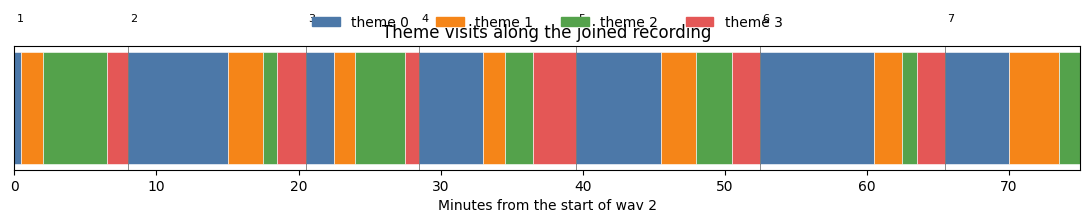

In [5]:
import matplotlib.pyplot as plt

colors = {0: "#4c78a8", 1: "#f58518", 2: "#54a24b", 3: "#e45756"}
fig, ax = plt.subplots(figsize=(11, 2.6))
for _, row in theme_table.iterrows():
    ax.barh(
        0,
        row.duration_min,
        left=row.start_min,
        height=0.55,
        color=colors[int(row.theme)],
        edgecolor="white",
        linewidth=0.4,
    )
for _, row in songs.iterrows():
    ax.axvline(row.start_min, color="black", linewidth=0.7, alpha=0.45)
    ax.text(row.start_min + 0.15, 0.42, str(int(row.song)), fontsize=8, color="black")
handles = [plt.Rectangle((0, 0), 1, 1, color=colors[k]) for k in range(4)]
ax.legend(handles, [f"theme {k}" for k in range(4)], ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.35))
ax.set_xlim(0, 75)
ax.set_yticks([])
ax.set_xlabel("Minutes from the start of wav 2")
ax.set_title("Theme visits along the joined recording")
fig.tight_layout()
plt.show()


In [6]:
published = [
    (1, 0.0, 8.0),
    (2, 8.0, 20.5),
    (3, 20.5, 28.5),
    (4, 28.5, 39.5),
    (5, 39.5, 52.5),
    (6, 52.5, 65.5),
    (7, 65.5, 75.0),
]
got = list(zip(songs["song"].astype(int), songs["start_min"].round(1), songs["end_min"].round(1)))
print("matches the published song intervals" if got == published else f"mismatch {got}")
order = themes["theme"].tolist()
print("theme order", order)
print("cycle holds", all((a + 1) % 4 == b for a, b in zip(order, order[1:])))


matches the published song intervals
theme order [0, 1, 2, 3, 0, 1, 2, 3, 0, 1, 2, 3, 0, 1, 2, 3, 0, 1, 2, 3, 0, 1, 2, 3, 0, 1, 2]
cycle holds True


Six songs contain one pass of the cycle 0, 1, 2, 3. The recording ends during theme 2 of the seventh song. Theme 0 is the motif-21 theme produced by merging the two neighboring motif-21 states of the five-theme fit. The boundary of each theme visit is the best edge of its 95% profile-likelihood set.
